# 4D-Var for Advection and Diffusion of a simple four-tracer NPZD model

In this notebook, we demonstrate variational data assimilation with MARINADE-NPZD, utilizing automatic differentiation. The variational method "Weak-constrained 4D-Var" from the ADDA package (Frion et al., 2026) is used for joint state-parameter estimation.

We consider a MARINADE-NPZD setup in the northern North Sea (see Burchard et al., 2005). The model solves the following biogeochemical transport equation,

$\frac{\partial c}{\partial t} = \underbrace{-w_{sinking} \frac{\partial c}{\partial z}}_{\text{advection (sinking)}} + \underbrace{\frac{\partial}{\partial z}\left(\nu\frac{\partial c}{\partial z}\right)}_{\text{diffusion (turbulence)}} + \underbrace{Q(c, T, S)}_{\text{BGC terms}}$,

for the tracer concentrations $c_i(t, z)$. The sinking velocity $w_{sinking}$ is a constant model parameter, and the temperature and salinity fields $T$ and $S$ as well as the turbulent diffusivity $\nu(t, z)$ are pre-computed by GOTM, so MARINADE only needs to integrate advection, diffusion and local biogeochemical (BGC) source and sink terms $Q(c, T, S)$.

The BGC terms are computed with the NPZD model described by Burchard et al. (2005). It describes the four state variables Nutrients (N), Phytoplankton (P), Zooplankton (Z) and Detritus (D). The model is summarized with the following equations:

$I_{opt} = min(par_0/4,\,I_{min})$

$r_{pd} = \begin{cases}
r_{pdl}, & I_{min}>par\\
r_{pdu}, & \text{else}
\end{cases}$

$primprod = r_{max} \frac{par}{I_{opt}} \exp(1-\frac{par}{I_{opt}})\frac{n}{\alpha+n}\,p$

$g = g_{max} (1 - \exp(-I_v^2p^2))\,z$

$\frac{\partial n}{\partial t} = -primprod + r_{pn}\,p + r_{zn}\,z + r_{dn}\,d$

$\frac{\partial p}{\partial t} = primprod - g - r_{pn}\,p - r_{pd}\,p$

$\frac{\partial z}{\partial t} = g - r_{zn}\,z - r_{zd}\,z$

$\frac{\partial d}{\partial t} = r_{pd}\,p + r_{zd}\,z - r_{dn}\,d$

### DOWNLOAD FORCING FILES FROM ZENODO

Pre-computed forcing files are required for running this notebook. They can be obtained on Zenodo: <https://zenodo.org/uploads/23670437>

Please save the folder *marinade_github_forcing_data* to the following location:

In [ ]:
base_folder = '/gpfs/work/nimtz/zenodo/'  # the directory of your Zenodo download
path = base_folder + 'marinade_github_forcing_data/nns_npzd/base_simulation_5+3y/'

## Setup the tracer simulation

At first, we import needed libraries and load pre-computed physical fields:

In [ ]:
import torch
from tensordict import TensorDict
import numpy as np
from matplotlib import pyplot as plt
from time import time as time_function
import os
os.chdir('..')

from adda.system.state import State
from adda.pt.variational import wc4dvar_single_window_pt as wc4dvar_single_window
from adda.observation.operators import random_sparse_noisy_obs, noisy_obs_from_mask
from adda.observation.data import MaskedStateObservationSet
from adda.util.initialization import interp_initialization
from adda.util.visualization import show_1dseqimg
from adda.probability.distributions import DiagonalGaussian

# import from the diffops/tridiag package
from marinade.fabm.gotm_npzd_model import GOTMNPZDModel
from marinade.fabm.gotm_light_model import GOTMLightModel
from marinade.gotm.gotm import initialize_gotm, TracerSimulationOperator

In [ ]:
filename = f'nns_annual.nc'
fabm_yaml_name = 'fabm.yaml'
gotm_yaml_name = f'gotm.yaml'

device = 'cuda'

param_transform = torch.nn.functional.softplus
# param_transform = torch.nn.functional.relu
# param_transform = lambda x: x
# param_opt = 1
param_opt = 0

In [ ]:
initialization_dict = initialize_gotm(path+gotm_yaml_name, path+fabm_yaml_name, path+filename, model_classes=[GOTMLightModel, GOTMNPZDModel], device='cpu', dtype='float64')

h, nu, dt, t, z, zi = [initialization_dict[key] for key in ("h", "nu", "dt", "t", "z", "zi")]

initial_state_pelagic = initialization_dict["init_state_tensors"][1]
ts_pelagic = initialization_dict["full_ts_tensors"][1]
dynamic_inputs = initialization_dict["dynamic_inputs"]

### Prepare MARINADE operators

In [ ]:
light_model, npzd_model = initialization_dict["models"]
npzd_model_gpu = GOTMNPZDModel.create_model_from_yaml_file(path_fabm=path+fabm_yaml_name, path_gotm=path+gotm_yaml_name, device=device)
light_model_gpu = GOTMLightModel.create_model_from_yaml_file(path_fabm=path+fabm_yaml_name, path_gotm=path+gotm_yaml_name, device=device)
light_model.repair_state = npzd_model.repair_state = light_model_gpu.repair_state = npzd_model_gpu.repair_state = True
coupled_model = light_model.couple(npzd_model)
coupled_model_gpu = light_model_gpu.couple(npzd_model_gpu)

forward_operator = TracerSimulationOperator(
    bc_up_type_dif="neumann", bc_down_type_dif="neumann", bc_up_value_dif=0., bc_down_value_dif=0.,
    bc_up_type_adv="flux", bc_down_type_adv="flux", bc_up_value_adv=0., bc_down_value_adv=0.,
    scheme_adv="p2_pdm", conserve=False, implicitness=1., allow_negative=False, model=coupled_model)
forward_operator_gpu = TracerSimulationOperator(
    bc_up_type_dif="neumann", bc_down_type_dif="neumann", bc_up_value_dif=0., bc_down_value_dif=0.,
    bc_up_type_adv="flux", bc_down_type_adv="flux", bc_up_value_adv=0., bc_down_value_adv=0.,
    scheme_adv="p2_pdm", conserve=False, implicitness=1., allow_negative=False, model=coupled_model_gpu)
parameters_reference = forward_operator.model.get_parameters().clone()

### Optional: check MARINADE simulation for consistency

The operators in MARINADE are PyTorch re-implementations of GOTM transport operators and FABM biogeochemical models. To check whether these re-implementations produce identical simulations as their Fortran originals, set *compare_simulation* to *True*. It might take a few minutes.

In [ ]:
compare_simulation = False
initial_state_dict = TensorDict({"pelagic": initial_state_pelagic}, batch_size=initial_state_pelagic.shape[:1])
initial_state_dict = light_model.compute_light(initial_state_dict, dt, dynamic_inputs[:, 0])
if compare_simulation:
    t0 = time_function()

    forward_operator.model.update_parameters(parameters_reference.clone().cpu())
    simulation = forward_operator.integrate(
        initial_state_dict,
        dt,
        h,
        nu,
        dynamic_inputs=dynamic_inputs,
    )
    print(f'Total time for the simulation: {time_function() - t0} seconds')

    simulation_tensor = simulation["pelagic"]
    fig, ax = plt.subplots(2, 2, sharex=True, sharey=True)
    ax_flat = [x for xs in ax for x in xs]
    for i, (label, _ax) in enumerate(zip(["npzd_nut", "npzd_phy", "npzd_zoo", "npzd_det"], ax_flat)):
        _diff = torch.tensor(simulation_tensor[:][...,i,:].squeeze() - ts_pelagic[0,:,i,:])
        _vmax = torch.max(torch.abs(_diff))
        cm = _ax.pcolormesh(t, z.T, _diff.T, vmin=-_vmax, vmax=_vmax, cmap='coolwarm')
        plt.colorbar(cm, ax=_ax, label=label)
    ax[1,0].set_xlabel("$t$ [s]"); ax[1,1].set_xlabel("$t$ [s]")
    ax[0,0].set_ylabel("$z$ [m]"); ax[1,0].set_ylabel("$z$ [m]")
    plt.show()

The simulation should reproduce the time series from the data file.

### Sample ground truth

In [ ]:
tuned_parameter_names = ["rmax", "gmax", "rpn", "rzn", "rdn", "rzd", "rpdu", "rpdl", "w_p", "w_d"] # , "w_p", "w_d", ]

parameter_scales = TensorDict({_p: parameters_reference[_p] for _p in tuned_parameter_names}) / param_transform(torch.tensor(param_opt).to(parameters_reference["alpha"]))

In [ ]:
torch.random.manual_seed(3) # 42)
parameters_init = TensorDict({_p: torch.tensor(param_opt, dtype=torch.float64, device=device) for _p in tuned_parameter_names}) # / parameter_scales
parameter_prior = DiagonalGaussian(parameters_init, 0.5 + 0 * parameters_init)
parameters_ground_truth = parameter_prior.sample()
log_probs = np.array([parameter_prior.log_prob(parameter_prior.sample()).item() for i in range(500)])
initial_parameters_scaled = parameters_init.apply(param_transform) * parameter_scales
ground_truth_parameters_scaled = parameters_ground_truth.apply(param_transform) * parameter_scales
for name in tuned_parameter_names:
    print(name.ljust(5), ' =', f'{parameters_ground_truth[name].item(): .10f}', ' bzw.', f'{ground_truth_parameters_scaled[name].item(): .10e}', f' ({initial_parameters_scaled[name].item(): .10e} )')

rmax   = -1.0313764202  bzw.  5.0915042278e-06  ( 1.1574074074e-05 )
gmax   = -0.3416364178  bzw.  1.7928424661e-06  ( 2.3148148148e-06 )
rpn    =  0.2665583731  bzw.  1.3947419068e-07  ( 1.1574074074e-07 )
rzn    = -0.9589810345  bzw.  5.4177846216e-08  ( 1.1574074074e-07 )
rdn    = -0.4689141300  bzw.  2.4341821705e-08  ( 3.4722222222e-08 )
rzd    = -0.0900886783  bzw.  2.1677728457e-07  ( 2.3148148148e-07 )
rpdu   = -0.5639108879  bzw.  1.5042279976e-07  ( 2.3148148148e-07 )
rpdl   =  0.4040748428  bzw.  1.5286168891e-06  ( 1.1574074074e-06 )
w_p    =  0.8682056862  bzw. -2.0348913882e-05  (-1.1574074074e-05 )
w_d    =  0.5928662518  bzw. -8.6235077837e-05  (-5.7870370370e-05 )


At the first notebook run, we need to generate the ground truth time series. Since that can be time-consuming, you might want to save the ground truth, so you will be able to load it at subsequent notebook runs.

In [ ]:
t0 = time_function()

forward_operator.model.update_parameters(parameters_reference.cpu().clone())
forward_operator.model.update_parameters(parameters_ground_truth.cpu().clone().apply(param_transform)*parameter_scales)
print('Starting model rollout for ground truth sampling...')
ts_ground_truth = forward_operator.integrate(
    initial_state_dict,
    dt,
    h,
    nu,
    dynamic_inputs=dynamic_inputs,
)
print(f'Total time for the ground truth rollout: {time_function() - t0} seconds')

Starting model rollout for ground truth sampling...
Total time for the ground truth rollout: 408.9678864479065 seconds


In [ ]:
import pickle
with open('ts_ground_truth.pkl', 'wb') as file:
    pickle.dump(ts_ground_truth, file)

In [ ]:
import pickle
with open('ts_ground_truth.pkl', 'rb') as file:
    ts_ground_truth = pickle.load(file)

We visualize the reference and ground truth time series:

In [ ]:
tracers = ["nut", "phy", "zoo", "det"]
cmaps = ["cividis", "viridis", "plasma", "bone"]

observed_t = t[:43824+1]
observed_dynamic_inputs = dynamic_inputs[:,:43824+1]
observed_dynamic_inputs_state = State(observed_dynamic_inputs.to(device), time_axis=observed_t.to(device))
observed_z = observed_dynamic_inputs["z"].squeeze()
observed_h = observed_dynamic_inputs['h']
observed_nu = observed_dynamic_inputs['nu']

reference_ts = ts_pelagic[:,:43824+1]
observed_ts_scale = torch.std(reference_ts, dim=(0, 1, 3), keepdims=True)
observed_ts_scale_flat = observed_ts_scale.squeeze()
observed_ts_scale = observed_ts_scale.to(device)
reference_ts = reference_ts / observed_ts_scale.to(reference_ts)
reference_forecast_ts = ts_pelagic[:,43824:] / observed_ts_scale.to(ts_ground_truth['pelagic'])
reference_ts_dict = TensorDict({"pelagic": reference_ts}, batch_size=reference_ts.shape[:2])
reference_ts_state = State(reference_ts_dict.to(device), time_axis=observed_t.to(device))

observed_ts = ts_ground_truth['pelagic'][:,:43824+1] / observed_ts_scale.to(ts_ground_truth['pelagic'])
observed_ts_dict = TensorDict({"pelagic": observed_ts}, batch_size=observed_ts.shape[:2])
observed_ts_state = State(observed_ts_dict.to(device), time_axis=observed_t.to(device))
observed_ts_state_cpu = State(observed_ts_dict.to('cpu'), time_axis=observed_t.to('cpu'))

forecast_t = t[43824:]
forecast_ts = ts_ground_truth['pelagic'][:,43824:] / observed_ts_scale.to(ts_ground_truth['pelagic'])
forecast_ts_dict = TensorDict({"pelagic": forecast_ts}, batch_size=forecast_ts.shape[:2])
forecast_ts_state = State(forecast_ts_dict.to('cpu'), time_axis=forecast_t.to('cpu'))
forecast_dynamic_inputs = dynamic_inputs[:,43824:]
forecast_dynamic_inputs_state = State(forecast_dynamic_inputs.to(device), time_axis=forecast_t.to(device))
forecast_z = forecast_dynamic_inputs["z"].squeeze()
forecast_h = forecast_dynamic_inputs['h']
forecast_nu = forecast_dynamic_inputs['nu']

difference_ref_gt = (reference_ts_dict.cpu() - observed_ts_state.fields.cpu())['pelagic'][0]

def show_tracer_ts(ts_, ax=None, title=None, label_colorbar=None,
                   cbar_rotation=None, cbar_labelpad=None, cbar_loc=None,
                   cmap=None, vmin=None, vmax=None, center_on_zero=False,
                   t_=observed_t, z_=observed_z, xlabel=None, shading=None,
                   x_stride=1, y_stride=1, aspect=20):
    if ax is None:
        ax = plt.gca()
    if isinstance(ts_, TensorDict):
        ts_ = ts_['pelagic']
    if center_on_zero:
        vmax_abs = torch.max(torch.abs(ts_[~ts_.isnan()]))
        vmin, vmax = -vmax_abs, vmax_abs
    pcol = ax.pcolormesh(t_[::x_stride]/60**2/24/365.25, z_.T[::y_stride, ::x_stride], ts_.squeeze().T[::y_stride, ::x_stride], cmap=cmap, vmin=vmin, vmax=vmax, shading=shading)
    cbar = plt.colorbar(pcol, ax=ax, aspect=aspect, label=label_colorbar)
    if cbar_rotation is not None:
        cbar.set_label(label_colorbar, rotation=cbar_rotation, labelpad=cbar_labelpad, loc=cbar_loc)
    #for i in range(0, z_.shape[1], z_.shape[1]//10):
        #ax.plot(t_/60**2, z_[:, i], ls='--', c='gray', label=f"layer {i}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("$z$ [m]")
    ax.set_title(title)

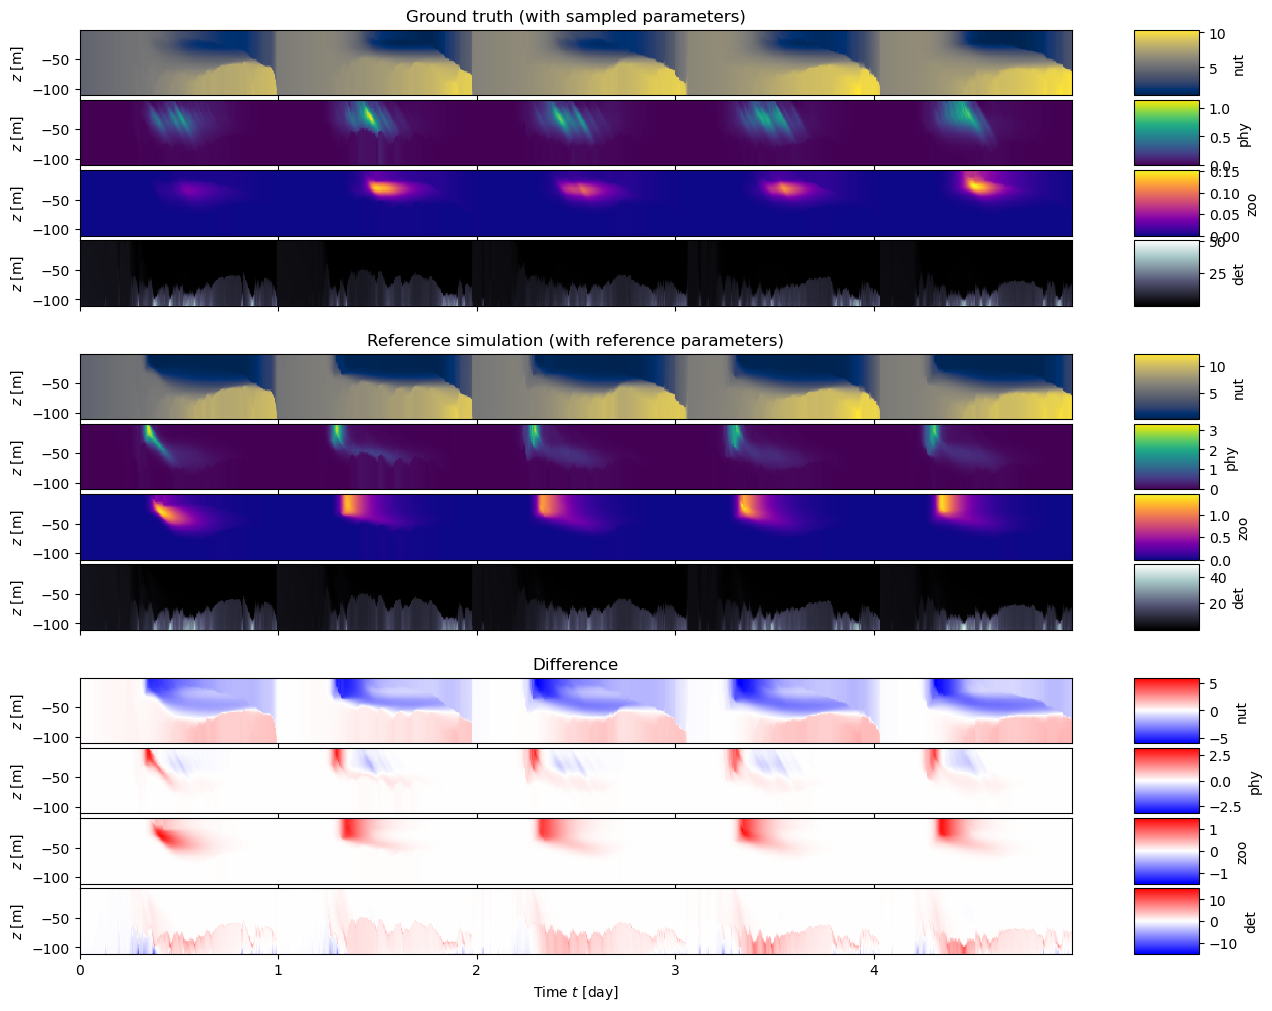

In [ ]:
fig, ax = plt.subplots(12, 1, sharex=True, figsize=(16,12))

titles_assimilated = ["Ground truth (with sampled parameters)", "Reference simulation (with reference parameters)", "Difference"]

idx = 1
for i in range(4):
    show_tracer_ts(observed_ts_state.fields['pelagic'].cpu()[0,:,i,:]*observed_ts_scale_flat[i], ax=ax[i], label_colorbar=tracers[i], cmap=cmaps[i], x_stride=10, y_stride=2, aspect=1)
    show_tracer_ts(reference_ts_state.fields["pelagic"].cpu()[0,:,i,:]*observed_ts_scale_flat[i], ax=ax[i+4], label_colorbar=tracers[i], cmap=cmaps[i], x_stride=10, y_stride=2, aspect=1)
    show_tracer_ts(difference_ref_gt.cpu()[:,i,:]*observed_ts_scale_flat[i], ax=ax[i+8], label_colorbar=tracers[i], cmap="bwr", center_on_zero=True, x_stride=10, y_stride=2, aspect=1)
for i in range(3):
    ax[4*i].set_title(titles_assimilated[i])
ax[-1].set_xlabel("Time $t$ [day]")

# collect colorbar axes (those without data limits)
cbar_axes = [
    a for a in fig.axes
    if a not in ax
]

inner_gap = 0.004
group_gap = 0.04

# read original geometry from the first axis
x0, _, w, _ = ax[0].get_position().bounds
top = ax[0].get_position().y1
bottom = ax[-1].get_position().y0

total_height = top - bottom
height = (total_height - 9*inner_gap - 2*group_gap) / 12

current_y = top

for g in range(3):
    for i in range(4):
        idx = g*4 + i
        idx_cbar = i*3 + g

        # move main axis
        ax_pos = [x0, current_y - height, w, height]
        ax[idx].set_position(ax_pos)

        # move corresponding colorbar
        cax = cbar_axes[idx_cbar]
        cx0, _, cw, _ = cax.get_position().bounds
        cax.set_position([cx0, current_y - height, cw, height])

        current_y -= height + inner_gap

    current_y -= group_gap - inner_gap

# Assimilate observations with weak-constraint 4D-Var

We attempt to assimilate states and parameters from sparse and noisy observations with the variational method 4D-Var. Specifically, we use a version of weak-constraint 4D-Var that has been extended for joint state-parameter estimation. With normalized system states $x$ and observations $y$, the observation operator $\mathcal{H}$, the time stepping operator $\mathcal{M}$, normalized parameter estimates $\theta$ and optimization parameters $\alpha$, $\beta$, $\boldsymbol{\sigma}_o$, $\boldsymbol{\sigma}_m$ and$\boldsymbol{\sigma}_\theta$, we minimize the loss:

$    \mathcal{L}_{\text{4D-Var}}(\hat{\mathbf{x}},\hat{\boldsymbol{\theta}})%,\mathbf{y})
    = %\underbrace
    {\sum_{t=1}^{n_t}\left\lVert\frac{\mathcal{H}(\hat{\mathbf{x}}_t)-\mathbf{y}_t}{\boldsymbol{\sigma}_o}\right\rVert_2^2}%_{\text{observation error}}
    +\,\alpha
    %\underbrace
    {\sum_{t=1}^{n_t-1}\left\lVert\frac{\mathcal{M}_{\boldsymbol{\lambda}(\hat{\boldsymbol{\theta}})}(\hat{\mathbf{x}}_t)-\hat{\mathbf{x}}_{t+1}}{\boldsymbol{\sigma}_m}\right\rVert_2^2}
    %_{\text{model error}} 
    + \beta\,n_t\,\bigg\lVert\frac{\hat{\boldsymbol{\theta}}}{\boldsymbol{\sigma}_\theta}\bigg\rVert_2^2$
    
We will minimize the loss iteratively with the optimizer _ADAM_, utilizing the automatic differentiation capabilities of MARINADE.

In [ ]:
data_std = torch.std(observed_ts, dim=(0, 1, 3)).unsqueeze(-1)
data_mean = torch.mean(observed_ts, dim=(0, 1, 3)).unsqueeze(-1)

In [ ]:
obs_noise_sd = {'pelagic': 0.01+0.0*data_std.squeeze().to(device=device)[None,None,:,None]} # the observations on the fast variables are less noisy (which reflects their smaller variability)

_mask = torch.full_like(observed_ts_state.fields.copy().to(dtype=torch.bool), False)
_mask['pelagic'][:,::24,:,:] = True
groundtruth, obs_op, observations = noisy_obs_from_mask(observed_ts_state, obs_noise_sd, _mask, mult_precision=torch.float64)
# set mult_precision=torch.float16 or remove it if memory is limited

_state = observations.state.fields.cpu().copy()
_mask = observations.mask
_mask = State(_mask.fields.cpu(), _mask.time_axis.cpu())
observations_cpu = MaskedStateObservationSet(State(_state,time_axis=observations.state.time_axis.cpu()), _mask)

# ensure concentrations are always non-negative
torch.clamp_min_(observations.state.fields['pelagic'], 0.)
torch.clamp_min_(observations_cpu.state.fields['pelagic'], 0.); pass

State(
    Fields: TensorDict(
        fields={
            pelagic: Tensor(shape=torch.Size([1, 43825, 4, 110]), device=cuda:0, dtype=torch.bool, is_shared=True)},
        batch_size=torch.Size([1, 43825]),
        device=None,
        is_shared=False)
    Time axis: tensor([0.0000e+00, 3.6000e+03, 7.2000e+03,  ..., 1.5776e+08, 1.5776e+08,
            1.5777e+08], device='cuda:0', dtype=torch.float64))


In [ ]:
n_steps = observed_ts_state.time_axis.nelement()

mu = TensorDict({"pelagic": torch.zeros(1, n_steps - 1, 4, h.shape[-1], device=device)})
sigma = TensorDict({"pelagic": obs_noise_sd["pelagic"].expand(1, n_steps-1, 4, h.shape[-1])})

model_error_distribs = DiagonalGaussian(mu, sigma)

We print the model parameters:

In [ ]:
print('parameter     reference value               ground truth')
print('--------------------------------------------------------')
for name, value in parameters_reference.items():
    print(name.ljust(10), '=', f'{value.item():15.11f}', ' =', f'{value.item(): .2e}',
          f'  ({forward_operator.model.get_parameters()[name].item(): .2e})' if name in parameters_ground_truth else '')

parameter     reference value               ground truth
--------------------------------------------------------
light_a    =   0.58000000000  =  5.80e-01 
light_g1   =   0.35000000000  =  3.50e-01 
light_g2   =  23.00000000000  =  2.30e+01 
p0         =   0.02250000000  =  2.25e-02 
z0         =   0.02250000000  =  2.25e-02 
kc         =   0.03000000000  =  3.00e-02 
i_min      =  25.00000000000  =  2.50e+01 
rmax       =   0.00001157407  =  1.16e-05   ( 5.09e-06)
gmax       =   0.00000231481  =  2.31e-06   ( 1.79e-06)
iv         =   1.10000000000  =  1.10e+00 
alpha      =   1.35000000000  =  1.35e+00 
rpn        =   0.00000011574  =  1.16e-07   ( 1.39e-07)
rzn        =   0.00000011574  =  1.16e-07   ( 5.42e-08)
rdn        =   0.00000003472  =  3.47e-08   ( 2.43e-08)
rpdu       =   0.00000023148  =  2.31e-07   ( 1.50e-07)
rpdl       =   0.00000115741  =  1.16e-06   ( 1.53e-06)
rzd        =   0.00000023148  =  2.31e-07   ( 2.17e-07)
dic_per_n  =   6.62500000000  =  6.62e+00 
w_p     

Next, we define a simple one-time-step function in order to fit the ADDA conventions.
In order to use the 4Dvar function, you should always have a function like this taking the state, dt, dynamic_inputs and static_inputs.


In [ ]:
tracer_keys_npzd = ["npzd_nut", "npzd_phy", "npzd_zoo", "npzd_det"]
observed_ts_scale_reshaped = observed_ts_scale[0]
def next_step_function(x: State, dt: float, dynamic_inputs: State, static_inputs: State, parameters: TensorDict=None):
    "this time stepping function expects the input State x to have a single field called 'pelagic'"
    B, T = x.fields.batch_size[:2]
    x_dict = x.fields.reshape(-1)
    dynamic_inputs_dict = dynamic_inputs.fields.reshape(-1)
    h_tensor = dynamic_inputs_dict['h']
    nu_tensor = dynamic_inputs_dict['nu']
    if h_tensor.shape[0] > x_dict.shape[0]:
        h_tensor = h_tensor[1:]
    if nu_tensor.shape[0] > x_dict.shape[0]:
        nu_tensor = nu_tensor[:-1]
    if dynamic_inputs_dict.shape[0] > x_dict.shape[0]:
        dynamic_inputs_dict = dynamic_inputs_dict[1:]
    x_dict["pelagic"] = x_dict["pelagic"] * observed_ts_scale_reshaped  # TODO
    if parameters is not None:
        forward_operator_gpu.model.update_parameters(parameters.fields[0][0].apply(param_transform)*parameter_scales)
    integrated = forward_operator_gpu(x_dict, dt.to(h_tensor.device), h_tensor, nu_tensor, dynamic_inputs=dynamic_inputs_dict)
    integrated = integrated.select(*x_dict.keys())
    integrated = integrated.reshape(B, T, *integrated.shape[1:])  # re-add batch dimension
    integrated["pelagic"] = integrated["pelagic"] / observed_ts_scale
    return State(integrated, time_axis=x.time_axis + dt)  # return State object, advancing time

State estimates can be initialized with either interpolations of observations or with the reference simulation. Change the following variable to choose between the two options.

In [ ]:
init_from_obs = False

Again, you can save the assimilation results, so you can load it on subsequent notebook runs (see cells below)

In [ ]:
# This should take a few minutes to run
loss_list = []
loss_component_list = []
parameter_list = []
forward_operator_gpu.model.update_parameters(parameters_reference.clone().to(device=device))
forward_operator.model.update_parameters(parameters_reference.clone().cpu())
if init_from_obs:
    _init = interp_initialization(observations_cpu, kind="linear")  # state estimate for all time points
    _init.fields = _init.fields.to(device)
else:
    _init = reference_ts_state
t0 = time_function()

nelement = obs_op.time_axis.nelement()

assimilated_states = wc4dvar_single_window(next_step_function, 
    observations,
    obs_op,
    model_error_distribs,
    x_init=_init,
    dynamic_inputs=observed_dynamic_inputs_state,
    param_init=State(parameters_init.unsqueeze(0).unsqueeze(0)),
    loss_list=loss_list,
    loss_component_list=loss_component_list,
    parameter_list=parameter_list,
    optimizer_class=torch.optim.Adam,
#    optimizer_class=LBFGSB,
#    optimizer_pars={'lr': 1e0, 'history_size': 15},
#    optimizer_pars={'lower_bound': lower_bound, 'upper_bound': None, 'history_size': 50},
    optimizer_pars={'lr': 1e-1},
    scheduler_class=torch.optim.lr_scheduler.LinearLR,
    scheduler_pars={'start_factor': 0.1, 'end_factor': 0.05, 'total_iters': 5000},
    alpha=1e2,
    beta=1e-2*nelement,
    param_prior=parameter_prior,
    n_steps=1000 if init_from_obs else 5000,
    verbose=1)

print(f'Total time for the 4Dvar optimization: {time_function() - t0} seconds')

assimilated_states, assimilated_parameters = assimilated_states
assimilated_parameters = assimilated_parameters.detach()
assimilated_states = assimilated_states.detach()

In [ ]:
with open('assimilated_states_parameters.pkl', 'wb') as file:
    pickle.dump(assimilated_states, file)
    pickle.dump(assimilated_parameters, file)
    pickle.dump(loss_list, file)
    pickle.dump(loss_component_list, file)
    pickle.dump(parameter_list, file)

In [ ]:
with open('assimilated_states_parameters.pkl', 'rb') as file:
    assimilated_states = pickle.load(file)
    assimilated_parameters = pickle.load(file)
    loss_list = pickle.load(file)
    loss_component_list = pickle.load(file)
    parameter_list = pickle.load(file)

We print the parameter estimates:

In [ ]:
assimilated_parameters_scaled = assimilated_parameters.fields[0,0].apply(param_transform) * parameter_scales
initial_parameters_scaled = parameters_init.apply(param_transform) * parameter_scales
ground_truth_parameters_scaled = parameters_ground_truth.apply(param_transform) * parameter_scales
print('param.    init. guess           final estimate      ground truth')
print('----------------------------------------------------------------------')
for name, value in assimilated_parameters_scaled.items():
    print(name.ljust(5), ' =', f'{initial_parameters_scaled[name].item(): .10e}', ' ->', f'{value.item(): .10e}', f' ({ground_truth_parameters_scaled[name].item(): .10e} )')

param.    init. guess           final estimate      ground truth
----------------------------------------------------------------------
rmax   =  1.1574074074e-05  ->  5.2536106751e-06  ( 5.0915042278e-06 )
gmax   =  2.3148148148e-06  ->  1.8049613553e-06  ( 1.7928424661e-06 )
rpn    =  1.1574074074e-07  ->  1.6074883624e-07  ( 1.3947419068e-07 )
rzn    =  1.1574074074e-07  ->  1.0161878787e-07  ( 5.4177846216e-08 )
rdn    =  3.4722222222e-08  ->  2.4814024650e-08  ( 2.4341821705e-08 )
rzd    =  2.3148148148e-07  ->  1.8047851975e-07  ( 2.1677728457e-07 )
rpdu   =  2.3148148148e-07  ->  2.7268574642e-07  ( 1.5042279976e-07 )
rpdl   =  1.1574074074e-06  ->  1.5168014320e-06  ( 1.5286168891e-06 )
w_p    = -1.1574074074e-05  -> -2.0295890537e-05  (-2.0348913882e-05 )
w_d    = -5.7870370370e-05  -> -8.6293042299e-05  (-8.6235077837e-05 )


Next, we plot the parameter estimate curve over optimization:

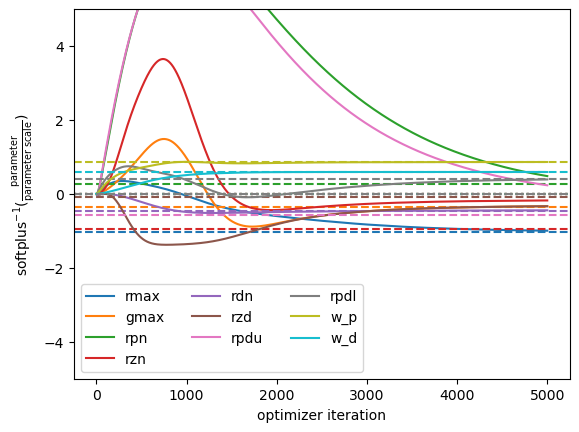

In [ ]:
parameter_list_stacked = torch.stack(parameter_list)
cmap = plt.get_cmap('tab10')
for i, _p in enumerate(tuned_parameter_names):
#    plt.plot(param_transform(parameter_list_stacked[_p]))
    plt.plot(parameter_list_stacked[_p][:,0,0], color=cmap(i), label=_p)
    plt.axhline(parameters_init[_p].cpu(), color=cmap(i), ls=':')
    plt.axhline(parameters_ground_truth[_p].cpu(), color=cmap(i), ls='--')
plt.axhline(param_opt, c="grey", ls="--")
#plt.yscale("log")
plt.ylim(-5, 5)
plt.legend(ncol=3)
plt.xlabel('optimizer iteration'); plt.ylabel(r'softplus$^{-1}$($\frac{\text{parameter}}{\text{parameter scale}}$)')
plt.show()

We compute state errors for initial and final estimates:

In [ ]:
valid_obs_x = observations.state.fields['pelagic'][0]
valid_obs_x[torch.logical_not(observations.mask.fields['pelagic'][0])] = torch.nan
errors_x = (assimilated_states.fields.cpu() - observed_ts_state.fields.cpu())['pelagic'][0]
errors_initialization = (_init.fields.cpu() - observed_ts_state.fields.cpu())['pelagic'][0]

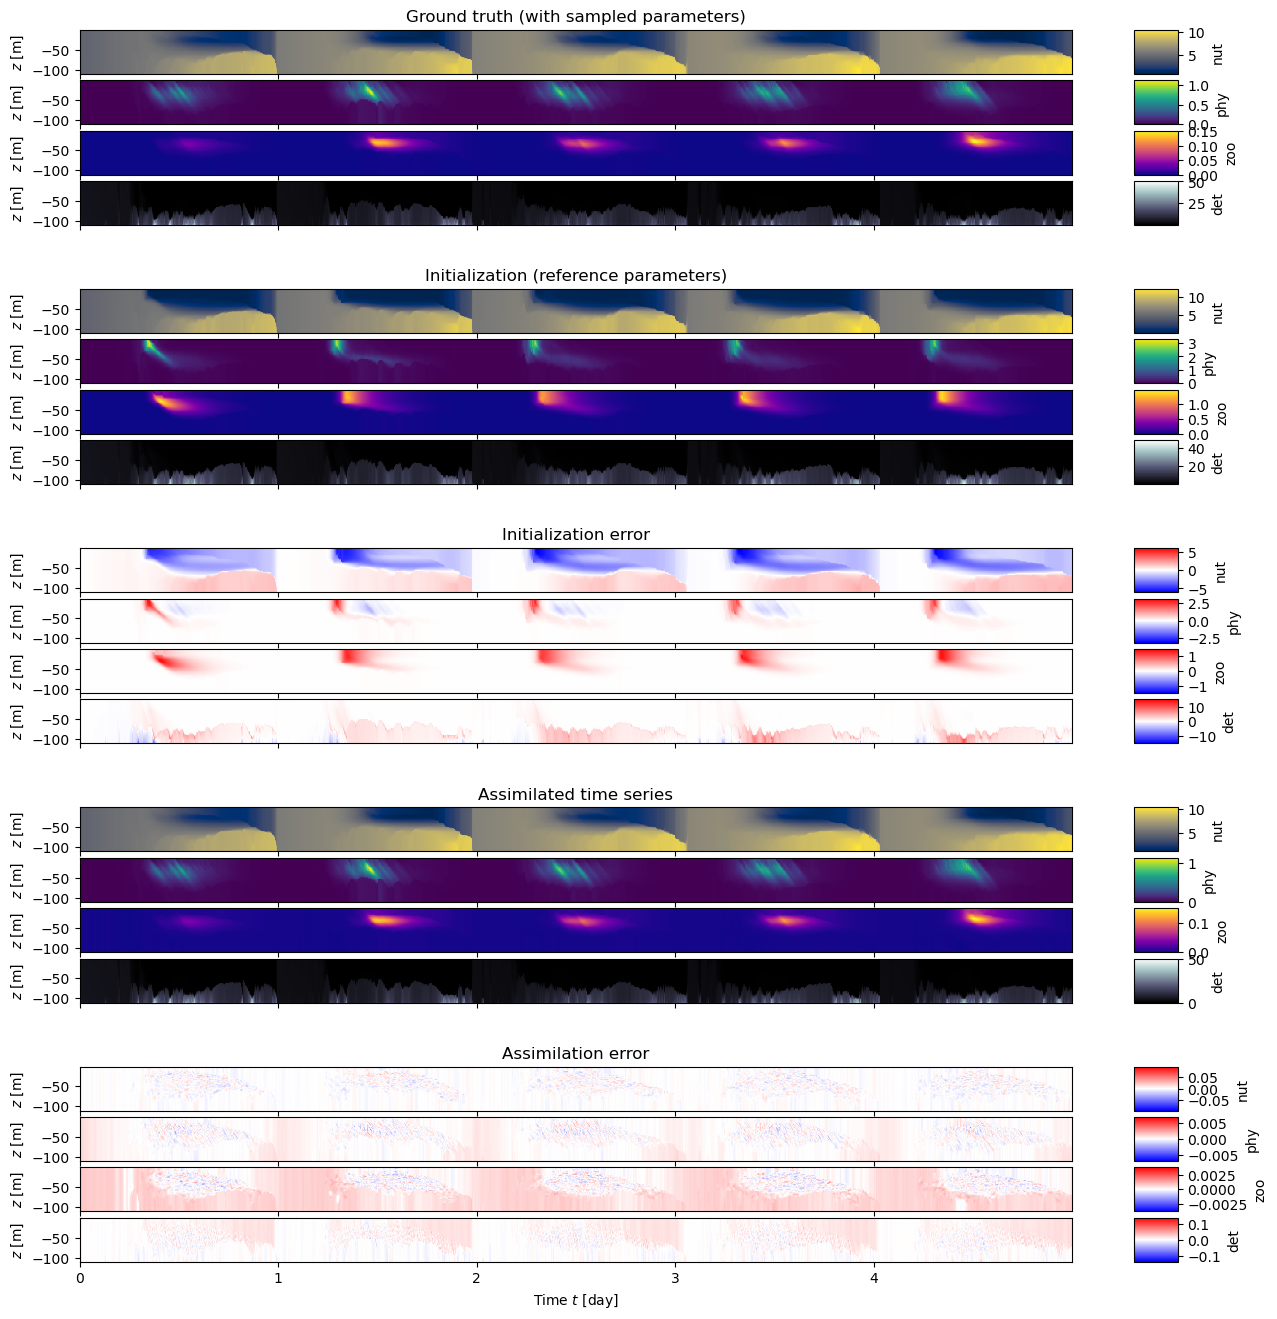

In [ ]:
fig, ax = plt.subplots(20, 1, sharex=True, figsize=(16,16))

titles_assimilated = ["Ground truth (with sampled parameters)", "Initialization (reference parameters)", "Initialization error", "Assimilated time series", "Assimilation error"]

idx = 1
for i in range(4):
    show_tracer_ts(observed_ts_state.fields['pelagic'].cpu()[0,:,i,:]*observed_ts_scale_flat[i], ax=ax[i], label_colorbar=tracers[i], cmap=cmaps[i], x_stride=10, y_stride=2, aspect=1)
    show_tracer_ts(_init.fields["pelagic"].cpu()[0,:,i,:]*observed_ts_scale_flat[i], ax=ax[i+4], label_colorbar=tracers[i], cmap=cmaps[i], x_stride=10, y_stride=2, aspect=1)
    show_tracer_ts(errors_initialization.cpu()[:,i,:]*observed_ts_scale_flat[i], ax=ax[i+8], label_colorbar=tracers[i], cmap="bwr", center_on_zero=True, x_stride=10, y_stride=2, aspect=1)
    show_tracer_ts(assimilated_states.fields["pelagic"].cpu()[0,:,i,:]*observed_ts_scale_flat[i], ax=ax[i+12], label_colorbar=tracers[i], cmap=cmaps[i], x_stride=10, y_stride=2, aspect=1)
    show_tracer_ts(errors_x.cpu()[:,i,:]*observed_ts_scale_flat[i], ax=ax[i+16], label_colorbar=tracers[i], cmap="bwr", center_on_zero=True, x_stride=10, y_stride=2, aspect=1)
for i in range(5):
    ax[4*i].set_title(titles_assimilated[i])
ax[-1].set_xlabel("Time $t$ [day]")

# collect colorbar axes (those without data limits)
cbar_axes = [
    a for a in fig.axes
    if a not in ax
]

inner_gap = 0.004
group_gap = 0.04

# read original geometry from the first axis
x0, _, w, _ = ax[0].get_position().bounds
top = ax[0].get_position().y1
bottom = ax[-1].get_position().y0

total_height = top - bottom
height = (total_height - 15*inner_gap - 4*group_gap) / 20

current_y = top

for g in range(5):
    for i in range(4):
        idx = g*4 + i
        idx_cbar = i*5 + g

        # move main axis
        ax_pos = [x0, current_y - height, w, height]
        ax[idx].set_position(ax_pos)

        # move corresponding colorbar
        cax = cbar_axes[idx_cbar]
        cx0, _, cw, _ = cax.get_position().bounds
        cax.set_position([cx0, current_y - height, cw, height])

        current_y -= height + inner_gap

    current_y -= group_gap - inner_gap

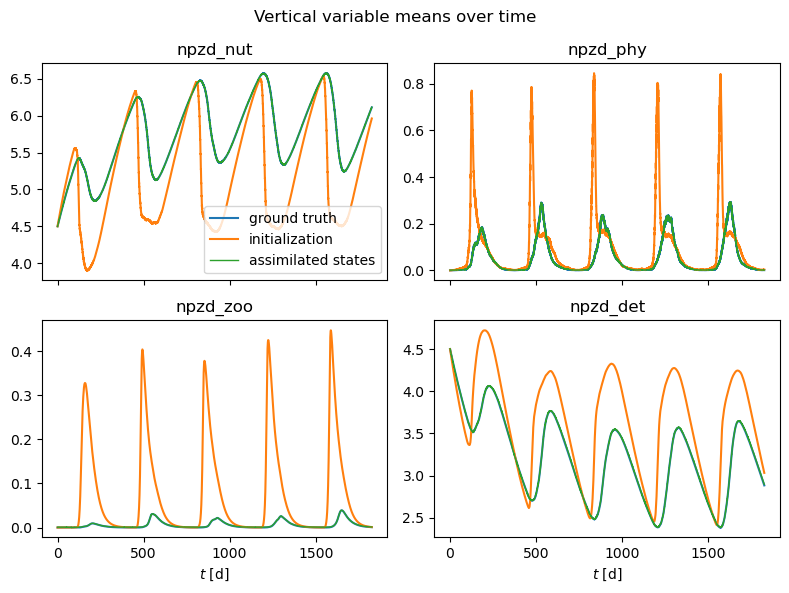

In [ ]:
fig, ax = plt.subplots(2, 2, sharex=True, figsize=(8, 6))
_vars = ["npzd_nut", "npzd_phy", "npzd_zoo", "npzd_det"]

for i, (_var, _ax) in enumerate(zip(_vars, ax.flat)):
    _ax.set_title(_var)
    _ax.plot(observed_t.cpu()[:]/60**2/24, ((observed_h.squeeze()*observed_ts[...,i,:].squeeze()*observed_ts_scale_flat[i].squeeze()).mean(axis=1)/observed_h.squeeze().mean(axis=1))[:].cpu(), c='C0', label='ground truth')
    _ax.plot(observed_t.cpu()[:]/60**2/24, ((observed_h.squeeze()*_init.fields['pelagic'].cpu()[0,:,i,:]*observed_ts_scale_flat[i].squeeze()).mean(axis=1)/observed_h.squeeze().mean(axis=1))[:].cpu(), c='C1', label='initialization')
    _ax.plot(observed_t.cpu()[:]/60**2/24, ((observed_h.squeeze()*assimilated_states.fields['pelagic'].cpu()[0,:,i,:]*observed_ts_scale_flat[i].squeeze()).mean(axis=1)/observed_h.squeeze().mean(axis=1))[:].cpu(), c='C2', lw=1, label='assimilated states')
ax[0,0].legend()
ax[1,0].set_xlabel("$t$ [d]"); ax[1,1].set_xlabel("$t$ [d]")
plt.suptitle('Vertical variable means over time')
plt.tight_layout()
plt.show()

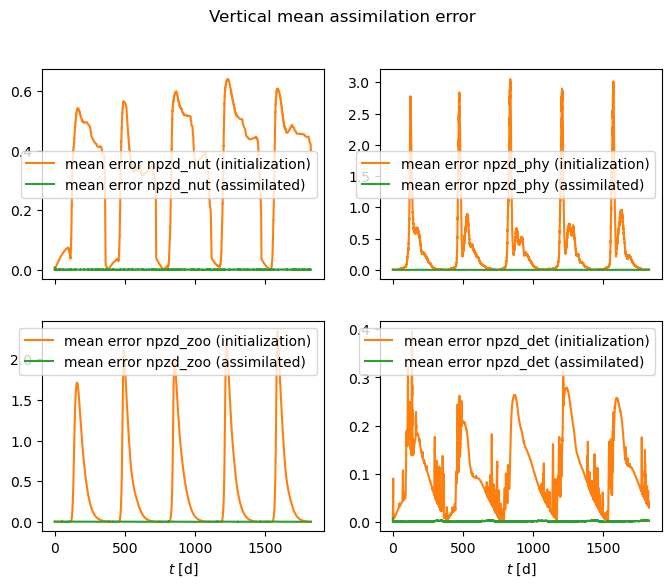

In [ ]:
fig, ax = plt.subplots(2, 2, sharex=True, figsize=(8, 6))
for i, (_var, _ax) in enumerate(zip(_vars, ax.flat)):
    _ax.plot(observed_t.cpu()[:]/60**2/24, ((observed_h.squeeze()*errors_initialization[:, i, :].abs().squeeze()).mean(axis=1)/observed_h.squeeze().mean(axis=1))[:], c='C1', label=f'mean error {_var} (initialization)')
    _ax.plot(observed_t.cpu()[:]/60**2/24, ((observed_h.squeeze()*errors_x[:, i, :].abs().squeeze()).mean(axis=1)/observed_h.squeeze().mean(axis=1))[:], c='C2', label=f'mean error {_var} (assimilated)')
    _ax.legend()
ax[1,0].set_xlabel("$t$ [d]"); ax[1,1].set_xlabel("$t$ [d]")
fig.suptitle('Vertical mean assimilation error')
plt.show()

Finally, we plot the loss curves:

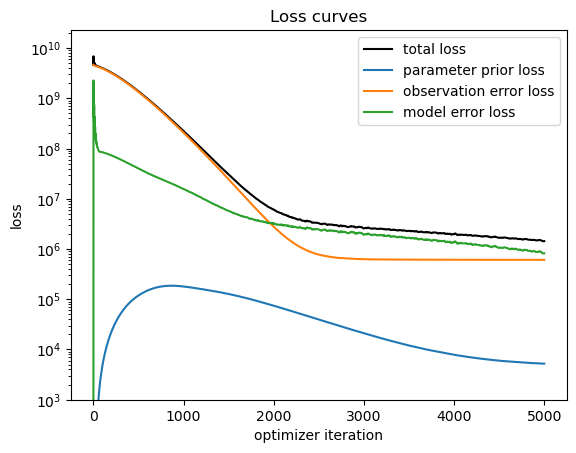

In [ ]:
plt.plot(loss_list, c='black', label='total loss')
plt.plot(loss_component_list, label=('parameter prior loss', 'observation error loss', 'model error loss'))
plt.yscale("log"); plt.xlabel('optimizer iteration'); plt.ylabel('loss'); plt.title('Loss curves')
plt.ylim(bottom=1e3); plt.legend(); plt.show()

### Compare forecast

With the assimilated states and parameters, we generate an improved forecast for a three-year period after the assimilation window:

In [ ]:
forecast_initial_state_dict = assimilated_states.fields.cpu()[:,-1]

In [ ]:
print('Starting forecast rollout...')
t0 = time_function()
_init_forecast = forecast_initial_state_dict.cpu().copy()
_init_forecast['pelagic'] = _init_forecast['pelagic']*observed_ts_scale.cpu()[:,0]
_init_forecast = light_model.compute_light(_init_forecast, dt, forecast_dynamic_inputs[:, 0])
forward_operator.model.update_parameters(assimilated_parameters_scaled.cpu().clone())
forecast = forward_operator.integrate(
    _init_forecast,
    dt,
    forecast_h,
    forecast_nu,
    dynamic_inputs=forecast_dynamic_inputs,
)
print(f'Rollout took {time_function() - t0} seconds')
forecast['pelagic'] /= observed_ts_scale.to(forecast['pelagic'].device)
forecast = State(forecast.select('pelagic').to(device), time_axis=forecast_t)

Starting forecast rollout...
Rollout took 154.86026430130005 seconds


In [ ]:
with open('forecast.pkl', 'wb') as file:
    pickle.dump(forecast, file)

In [ ]:
with open('forecast.pkl', 'rb') as file:
    forecast = pickle.load(file)

In [ ]:
errors_forecast = (forecast.fields.cpu() - forecast_ts_state.fields.cpu())['pelagic'][0]

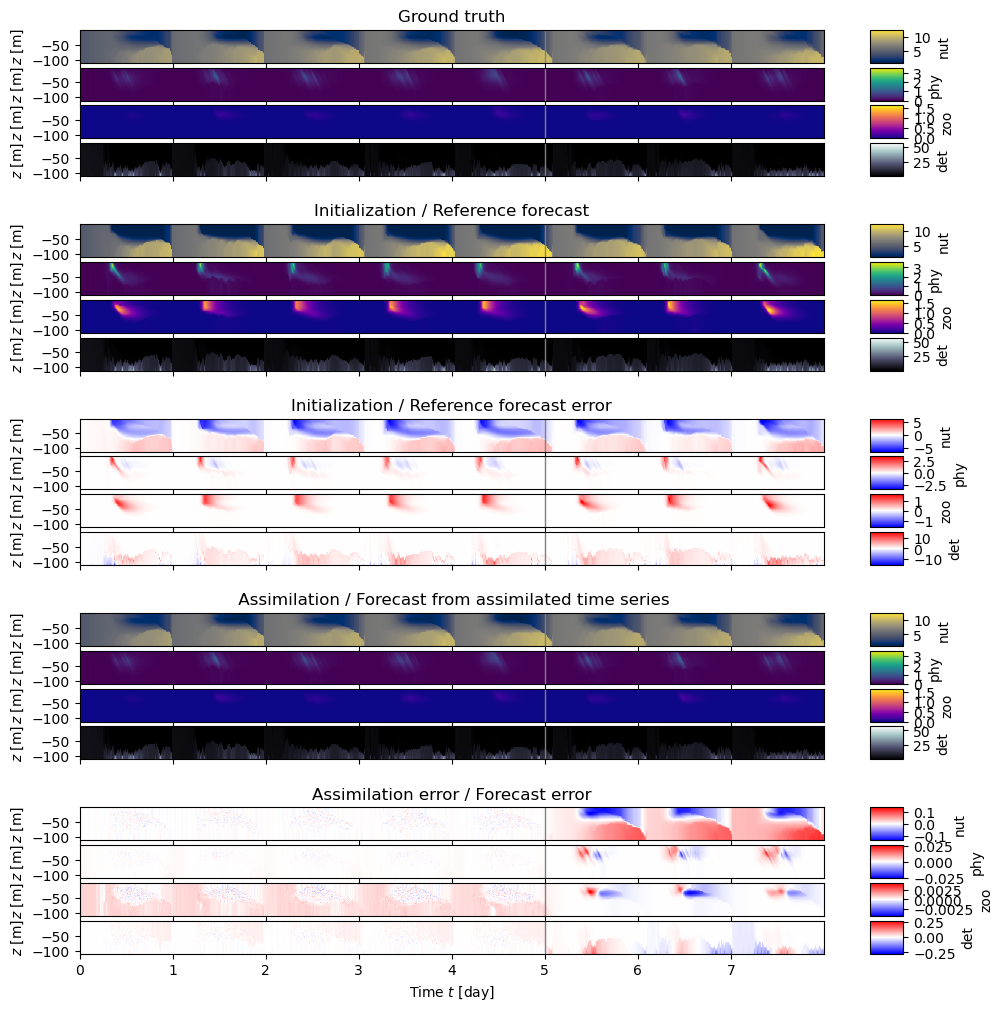

In [ ]:
errors_reference_forecast = (reference_forecast_ts.cpu() - forecast_ts_dict['pelagic'].cpu())[0]

fig, ax = plt.subplots(20, 1, sharex=True, figsize=(12,12))

titles_assimilated = ["Ground truth", "Initialization / Reference forecast", "Initialization / Reference forecast error", " Assimilation / Forecast from assimilated time series", "Assimilation error / Forecast error"]

idx = 1
for i in range(4):
    _ts_gt = torch.cat([observed_ts_dict['pelagic'].cpu()[0,:,i,:], forecast_ts_dict['pelagic'].cpu()[0,1:,i,:]])*observed_ts_scale_flat[i]
    _ts_ref = torch.cat([_init.fields["pelagic"].cpu()[0,:,i,:], reference_forecast_ts.cpu()[0,1:,i,:]])*observed_ts_scale_flat[i]
    _ts_res = torch.cat([assimilated_states.fields['pelagic'].cpu()[0,:,i,:], forecast.fields['pelagic'].cpu()[0,1:,i,:]])*observed_ts_scale_flat[i]
    _vmax = max(_ts_gt.max(), _ts_ref.max(), _ts_res.max())
    _vmin = max(_ts_gt.min(), _ts_ref.min(), _ts_res.min())
    show_tracer_ts(_ts_gt, t_=t, z_=z, ax=ax[i], label_colorbar=tracers[i], cmap=cmaps[i], vmax=_vmax, vmin=_vmin, x_stride=10, y_stride=2, aspect=1)
    show_tracer_ts(_ts_ref, t_=t, z_=z, ax=ax[i+4], label_colorbar=tracers[i], cmap=cmaps[i], vmax=_vmax, vmin=_vmin, x_stride=10, y_stride=2, aspect=1)
    show_tracer_ts(torch.cat([errors_initialization.cpu()[:,i,:], errors_reference_forecast.cpu()[1:,i,:]])*observed_ts_scale_flat[i], t_=t, z_=z, ax=ax[i+8], label_colorbar=tracers[i], cmap="bwr", center_on_zero=True, x_stride=10, y_stride=2, aspect=1)
    show_tracer_ts(_ts_res, t_=t, z_=z, ax=ax[i+12], label_colorbar=tracers[i], cmap=cmaps[i], vmax=_vmax, vmin=_vmin, x_stride=10, y_stride=2, aspect=1)
    show_tracer_ts(torch.cat([errors_x.cpu()[:,i,:], errors_forecast.cpu()[1:,i,:]])*observed_ts_scale_flat[i], t_=t, z_=z, ax=ax[i+16], label_colorbar=tracers[i], cmap="bwr", center_on_zero=True, x_stride=10, y_stride=2, aspect=1)
for i in range(5):
    ax[4*i].set_title(titles_assimilated[i])
ax[-1].set_xlabel("Time $t$ [day]")
for _ax in ax.flat:
    _ax.axvline(5, c='grey', lw=1)

# collect colorbar axes (those without data limits)
cbar_axes = [
    a for a in fig.axes
    if a not in ax
]

inner_gap = 0.004
group_gap = 0.04

# read original geometry from the first axis
x0, _, w, _ = ax[0].get_position().bounds
top = ax[0].get_position().y1
bottom = ax[-1].get_position().y0

total_height = top - bottom
height = (total_height - 15*inner_gap - 4*group_gap) / 20

current_y = top

for g in range(5):
    for i in range(4):
        idx = g*4 + i
        idx_cbar = i*5 + g

        # move main axis
        ax_pos = [x0, current_y - height, w, height]
        ax[idx].set_position(ax_pos)

        # move corresponding colorbar
        cax = cbar_axes[idx_cbar]
        cx0, _, cw, _ = cax.get_position().bounds
        cax.set_position([cx0, current_y - height, cw, height])

        current_y -= height + inner_gap

    current_y -= group_gap - inner_gap